## **GeoZL low-level API**

`geozl.graph` builds from a fixed menu, one predictor followed by one backend. Every GeoZL codec is also an [OpenZL](https://github.com/facebook/openzl) node, so when the chain you want is not on that menu you can wire it yourself with [`openzl.ext`](https://openzl.org/api/py/introduction/). OpenZL's [concepts page](https://openzl.org/getting-started/concepts/) explains nodes and graphs. This notebook works on the same Copernicus DEM tile as the [high-level notebook](https://asterisk.coop/geozl/notebooks/high-level-api.html).

In [ ]:
%pip install -q -U geozl rasterio

In [1]:
import time

import geozl
import matplotlib.pyplot as plt
import numpy as np
import openzl.ext as zl
import rasterio
from rasterio.windows import Window

geozl.__version__

'0.32.0'

### **The tile**

A 512×512 window of the Copernicus GLO-30 DEM over the French Alps, elevation in whole metres as int16.

In [2]:
url = ("https://copernicus-dem-30m.s3.amazonaws.com/"
       "Copernicus_DSM_COG_10_N45_00_E006_00_DEM/"
       "Copernicus_DSM_COG_10_N45_00_E006_00_DEM.tif")
with rasterio.open(url) as src:
    tile = np.round(src.read(1, window=Window(1000, 1000, 512, 512))).astype(np.int16)

W = tile.shape[1]
raw = tile.nbytes
print(tile.shape, tile.dtype, f"{raw/1e6:.2f} MB")

(512, 512) int16 0.52 MB


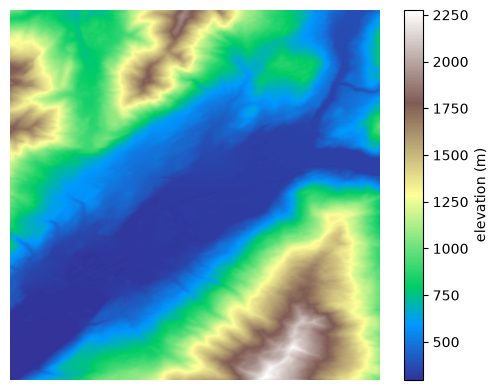

In [3]:
plt.imshow(tile, cmap="terrain")
plt.colorbar(label="elevation (m)")
plt.axis("off")
plt.show()

### **Two helpers**

OpenZL keeps the graph in a [`Compressor`](https://openzl.org/api/py/compressor/) and runs it with a [`CCtx`](https://openzl.org/api/py/compress/). `encode` sets both up for a graph passed in as a function. `decode` reads a frame with a [`DCtx`](https://openzl.org/api/py/decompress/) and GeoZL's decoders registered, since OpenZL does not know them otherwise.

The format version line is required, and OpenZL refuses the graph without it. `lossy=True` turns off the content checksum, which a quantizer needs. Both are listed on OpenZL's [parameters page](https://openzl.org/api/py/parameters/).

In [4]:
def encode(build, arr, lossy=False):
    c = zl.Compressor()
    c.select_starting_graph(build(c))
    cctx = zl.CCtx()
    cctx.ref_compressor(c)
    cctx.set_parameter(zl.CParam.FormatVersion, zl.MAX_FORMAT_VERSION)
    if lossy:
        cctx.set_parameter(zl.CParam.ContentChecksum, 2)
    data = zl.Input(zl.Type.Numeric, arr.reshape(-1))
    return bytes(cctx.compress([data]))


def decode(frame, dtype):
    dctx = zl.DCtx()
    geozl.register_decoders(dctx)
    return dctx.decompress(frame)[0].content.as_nparray().view(dtype)

### **A recipe by hand**

`planar>zigzag>entropy` from the menu, written as nodes. `Planar` is GeoZL's, [`Zigzag`](https://openzl.org/api/py/codecs/zigzag/) and [`Entropy`](https://openzl.org/api/py/codecs/entropy/) are OpenZL's. Each node takes the compressor and the node after it, so the code starts from the tail.

![The data flows from Planar to Zigzag to Entropy, while the code builds Entropy first, Zigzag second and Planar last.](https://asterisk.coop/geozl/notebooks/low-level-tail.svg)

In [5]:
frame = encode(
    lambda c: geozl.lossless.Planar(W)(c, zl.nodes.Zigzag()(c, zl.graphs.Entropy()(c))),
    tile)
menu = geozl.compress(tile, graph=geozl.graph(tile, "planar>zigzag>entropy"))

print(f"by hand  {len(frame):7,} bytes")
print(f"menu     {len(menu):7,} bytes")
print(np.array_equal(decode(frame, tile.dtype).reshape(tile.shape), tile))

by hand  116,730 bytes
menu     116,474 bytes
True


The two frames come out within a few hundred bytes of each other, and the hand-built one decodes to the same tile.

### **Any backend after the predictor**

The tail can be any OpenZL graph, including ones the menu does not list, such as `Huffman`, `Fse` or `Bitpack`. OpenZL's [codec list](https://openzl.org/api/py/codecs/introduction/) has them all. The loop keeps `Planar` and `Zigzag` and swaps the last step, then times `geozl.decompress` on each frame.

In [6]:
TAILS = {
    "Entropy": lambda c: zl.graphs.Entropy()(c),
    "Huffman": lambda c: zl.graphs.Huffman()(c),
    "Fse": lambda c: zl.graphs.Fse()(c),
    "Zstd": lambda c: zl.graphs.Zstd()(c),
    "FieldLz": lambda c: zl.graphs.FieldLz()(c),
    "Bitpack": lambda c: zl.graphs.Bitpack()(c),
    "Pfor": lambda c: geozl.lossless.Pfor()(c, zl.graphs.Store()(c)),
}


def best_decode(frame, reps=5):
    best = float("inf")
    for _ in range(reps):
        t = time.perf_counter()
        geozl.decompress(frame)
        best = min(best, time.perf_counter() - t)
    return raw / best / 1e6


def planar_zigzag(tail):
    return lambda c: geozl.lossless.Planar(W)(c, zl.nodes.Zigzag()(c, tail(c)))


print(f"{'tail':8} {'ratio':>6} {'decode MB/s':>12}")
for name, tail in TAILS.items():
    f = encode(planar_zigzag(tail), tile)
    print(f"{name:8} {raw/len(f):6.2f} {best_decode(f):12,.0f}")

tail      ratio  decode MB/s
Entropy    4.49        2,137
Huffman    4.49        2,141
Fse        3.37        1,007
Zstd       3.39        1,198
FieldLz    3.71        1,334
Bitpack    1.45        1,819
Pfor       3.79        6,126


Here `Huffman` ties `Entropy` on size, and `Pfor` decodes about three times faster for a lower ratio.

### **A lossy chain**

The quantizer is one more node. Here [`QuantLinear`](https://asterisk.coop/geozl/api-python.html#lossy) rounds the tile to a 2 m grid before [`PlanarZigzag`](https://asterisk.coop/geozl/api-python.html#lossless) and [`Entropy`](https://openzl.org/api/py/codecs/entropy/). The [near-lossless page](https://asterisk.coop/geozl/near-lossless.html) describes the `LINEAR` recipe it takes.

The node resolves its grid from each tile it encodes. There is no shared range and no check across tiles, as there is with [`geozl.graph(..., error=2)`](https://asterisk.coop/geozl/api-python.html#graph).

In [7]:
def lossy(c):
    tail = geozl.lossless.PlanarZigzag(W)(c, zl.graphs.Entropy()(c))
    return geozl.lossy.QuantLinear("LINEAR:MAX_ERROR=2", tile.dtype)(c, tail)


frame = encode(lossy, tile, lossy=True)
back = decode(frame, tile.dtype).reshape(tile.shape)
err = np.abs(back.astype(np.int32) - tile).max()
print(f"{raw/len(frame):.2f}x  max error {err} m")

8.14x  max error 2 m


### **Reading frames back**

A low-level frame is an ordinary OpenZL frame. `decode` reads it through [`openzl.ext`](https://openzl.org/api/py/introduction/), and `geozl.decompress` reads it with the C library and no graph at all.

In [8]:
a = decode(frame, tile.dtype)
b = geozl.decompress(frame).view(tile.dtype)
np.array_equal(a, b)

True

The [Python reference](https://asterisk.coop/geozl/api-python.html#lossless) lists every GeoZL node and its arguments, and the code is in [`geozl/lossless`](https://github.com/asterisk-labs/geozl/blob/main/bindings/python/geozl/lossless) and [`geozl/lossy`](https://github.com/asterisk-labs/geozl/blob/main/bindings/python/geozl/lossy). On the OpenZL side, the [Python quick start](https://openzl.org/getting-started/examples/py/quick-start/) builds a first graph step by step, and the code for `openzl.ext` is in [`py/ext/openzl`](https://github.com/facebook/openzl/tree/dev/py/ext/openzl).

---

<p align="center">Part of Earth Compress, led by Asterisk Labs and the National Oceanography Centre and funded by ARIA.</p>

<p align="center">
  <a href="https://asterisk.coop"><img src="https://asterisk.coop/geozl/assets/svg/partners/asterisk.svg" alt="Asterisk Labs" height="22"></a>
  &nbsp;&nbsp;&nbsp;&nbsp;
  <a href="https://asterisk.coop/project-pages/earth-compress.html"><img src="https://asterisk.coop/geozl/assets/svg/partners/earth-compress.svg" alt="Earth Compress" height="24"></a>
  &nbsp;&nbsp;&nbsp;&nbsp;
  <a href="https://noc.ac.uk/"><img src="https://asterisk.coop/geozl/assets/svg/partners/noc.svg" alt="National Oceanography Centre" height="34"></a>
  &nbsp;&nbsp;&nbsp;&nbsp;
  <a href="https://www.aria.org.uk/"><img src="https://asterisk.coop/geozl/assets/svg/partners/aria.svg" alt="ARIA" height="32"></a>
</p>